In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import networkx as nx

https://plotivy.app/charts/arc-diagram

https://www.data-to-viz.com/graph/arc.html

In [2]:
# https://github.com/TheMLGuy/Game-of-Thrones-Dataset
battles = pd.read_csv('data/battles.csv')
battles.head()

,name,year,battle_number,attacker_king,defender_king,attacker_1,attacker_2,attacker_3,attacker_4,defender_1,...,major_death,major_capture,attacker_size,defender_size,attacker_commander,defender_commander,summer,location,region,note
0,Battle of the Golden Tooth,298,1,Joffrey/Tommen Baratheon,Robb Stark,Lannister,NaN,NaN,NaN,Tully,...,1.0,0.0,15000.0,4000.0,Jaime Lannister,"Clement Piper, Vance",1.0,Golden Tooth,The Westerlands,NaN
1,Battle at the Mummer's Ford,298,2,Joffrey/Tommen Baratheon,Robb Stark,Lannister,NaN,NaN,NaN,Baratheon,...,1.0,0.0,NaN,120.0,Gregor Clegane,Beric Dondarrion,1.0,Mummer's Ford,The Riverlands,NaN
2,Battle of Riverrun,298,3,Joffrey/Tommen Baratheon,Robb Stark,Lannister,NaN,NaN,NaN,Tully,...,0.0,1.0,15000.0,10000.0,"Jaime Lannister, Andros Brax","Edmure Tully, Tytos Blackwood",1.0,Riverrun,The Riverlands,NaN
3,Battle of the Green Fork,298,4,Robb Stark,Joffrey/Tommen Baratheon,Stark,NaN,NaN,NaN,Lannister,...,1.0,1.0,18000.0,20000.0,"Roose Bolton, Wylis Manderly, Medger Cerwyn, H...","Tywin Lannister, Gregor Clegane, Kevan Lannist...",1.0,Green Fork,The Riverlands,NaN
4,Battle of the Whispering Wood,298,5,Robb Stark,Joffrey/Tommen Baratheon,Stark,Tully,NaN,NaN,Lannister,...,1.0,1.0,1875.0,6000.0,"Robb Stark, Brynden Tully",Jaime Lannister,1.0,Whispering Wood,The Riverlands,NaN


### Relación de batallas --> atacante vs. defensor

In [3]:
battles.groupby('attacker_king')['defender_king'].value_counts()

attacker_king             defender_king           
Balon/Euron Greyjoy       Robb Stark                   4
                          Joffrey/Tommen Baratheon     2
                          Balon/Euron Greyjoy          1
Joffrey/Tommen Baratheon  Robb Stark                  10
                          Stannis Baratheon            2
                          Balon/Euron Greyjoy          1
Robb Stark                Joffrey/Tommen Baratheon     9
                          Balon/Euron Greyjoy          1
Stannis Baratheon         Joffrey/Tommen Baratheon     2
                          Balon/Euron Greyjoy          1
                          Mance Rayder                 1
                          Renly Baratheon              1
Name: count, dtype: int64

In [4]:
battles = battles[['attacker_king', 'defender_king']].dropna()
battles.head(15)

,attacker_king,defender_king
0,Joffrey/Tommen Baratheon,Robb Stark
1,Joffrey/Tommen Baratheon,Robb Stark
2,Joffrey/Tommen Baratheon,Robb Stark
3,Robb Stark,Joffrey/Tommen Baratheon
4,Robb Stark,Joffrey/Tommen Baratheon
5,Robb Stark,Joffrey/Tommen Baratheon
6,Joffrey/Tommen Baratheon,Robb Stark
7,Balon/Euron Greyjoy,Robb Stark
8,Balon/Euron Greyjoy,Robb Stark
9,Balon/Euron Greyjoy,Robb Stark


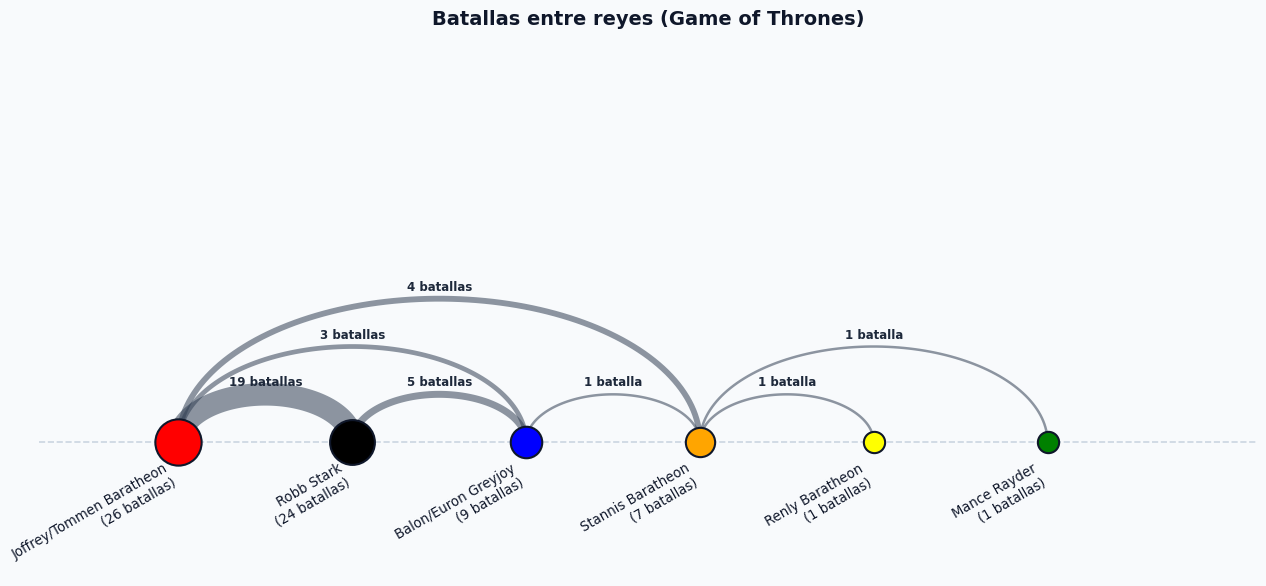

In [5]:
# construimos el grafo con NetworkX
G = nx.Graph()

for _, row in battles.iterrows():
    u, v = row['attacker_king'], row['defender_king']
    # Hay enfrentamientos internos (mismo atacante y defensor), los quitamos para evitar bucles
    if u == v:
        continue
    if G.has_edge(u, v):
        G[u][v]['weight'] += 1
    else:
        G.add_edge(u, v, weight=1)

# Ordenamos los nodos según el número total de batallas
degrees = dict(G.degree(weight='weight'))
ordered_nodes = sorted(G.nodes(), key=lambda n: degrees[n], reverse=True)

# Todos los nodos en el eje x (horizontal)
pos = {node: (i, 0.0) for i, node in enumerate(ordered_nodes)}

# Colores para mostrar
king_colors = {
    'Joffrey/Tommen Baratheon': 'red',
    'Robb Stark': 'black',
    'Balon/Euron Greyjoy': 'blue',
    'Stannis Baratheon': 'orange',
    'Mance Rayder': 'green',
    'Renly Baratheon': 'yellow',
}

# Creamos figura y axis de Matplotlib
gris = '#f8fafc'
fig, ax = plt.subplots(figsize=(13, 6), facecolor=gris)
ax.set_facecolor(gris)

# Arcos entre las aristas de NetworkX
theta = np.linspace(0, np.pi, 100)
for u, v, attrs in G.edges(data=True):
    x1, _ = pos[u]
    x2, _ = pos[v]
    weight = attrs['weight']

    mid_x = (x1 + x2) / 2.0
    radius = abs(x2 - x1) / 2.0
    height = radius * 0.75  # Estiliza un poco el arco

    # Curva del arco
    arc_x = mid_x + radius * np.cos(theta)
    arc_y = height * np.sin(theta)

    gris_oscuro = '#334155'
    lw = 1.0 + (weight * 0.8)
    ax.plot(arc_x, arc_y, color=gris_oscuro, linewidth=lw, alpha=0.55, zorder=2)

    # Etiqueta con el nº de batallas en cada nodo
    label = f'{weight} batallas' if weight > 1 else '1 batalla'
    ax.text(
        mid_x,
        height + 0.04,
        label,
        ha='center',
        va='bottom',
        fontsize=8.5,
        color='#1e293b',
        fontweight='bold',
    )

# Dibujar nodos de NetworkX
for node, (x, y) in pos.items():
    color = king_colors.get(node, '#334155')
    size = 200 + degrees[node] * 35  # Tamaño del nodo según su grado en G
    ax.scatter(
        x,
        y,
        s=size,
        color=color,
        edgecolors='#0f172a',
        linewidth=1.5,
        zorder=5,
    )

    label_text = f'{node}\n({degrees[node]} batallas)'
    ax.text(
        x,
        -0.15,
        label_text,
        rotation=30,
        ha='right',
        va='top',
        fontsize=9.5,
        fontweight='medium',
        color='#0f172a',
    )

# Línea base del eje
ax.axhline(0, color='#cbd5e1', linewidth=1.2, linestyle='--', zorder=1)

# Límites del gráfico (aunque es pequeño y ya se ve bastante bien)
ax.set_xlim(-0.8, len(ordered_nodes) + 0.2)
ax.set_ylim(-0.8, len(ordered_nodes) * 0.5)
ax.axis("off")

plt.title(
    'Batallas entre reyes (Game of Thrones)',
    fontsize=14,
    weight='bold',
    pad=25,
    color='#0f172a',
)
plt.tight_layout()
# plt.savefig('img/arc_diagram.png')
plt.show()